# Тренувальний ноутбук: лінійна регресія та регуляризація

**Курс:** Машинне навчання  
**Тема:** Linear Regression, Ridge, Lasso, Elastic Net

Цей ноутбук відповідає лекції про лінійну регресію та побудований як практичне продовження теоретичного матеріалу. У прикладах послідовно розглядаються проста й множинна лінійна регресія, метрики, залишки, недонавчання і перенавчання, L1/L2-регуляризація, Ridge, Lasso, Elastic Net, масштабування, крос-валідація, `GridSearchCV`, `Pipeline`, `ColumnTransformer` та навчальні криві.

У ноутбуці є два типи комірок:

- **Приклад** : готовий код, який потрібно виконати, проаналізувати та пояснити.
- **Самостійне завдання** : окрема кодова комірка з позначкою `TODO`. Її потрібно заповнити власноруч. Готового розв'язку в ноутбуці немає.

Рекомендація: виконувати комірки послідовно зверху вниз і після кожного блоку формулювати короткий висновок своїми словами.

## 0. Імпорт бібліотек і налаштування середовища

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)
from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    GridSearchCV,
    learning_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('Середовище готове до роботи.')

Середовище готове до роботи.


## 1. Проста лінійна регресія

Для однієї ознаки модель має вигляд

$$
\hat y = b_0 + b_1x.
$$

Тут $b_0$ : вільний член, а $b_1$ показує, на скільки одиниць у середньому змінюється прогноз $\hat y$ при збільшенні $x$ на одну одиницю.

Нижче згенеруємо дані, у яких істинна залежність приблизно дорівнює $y=5+2.4x$, але спостереження містять випадковий шум.

Вільний член b0: 4.907
Коефіцієнт b1: 2.451


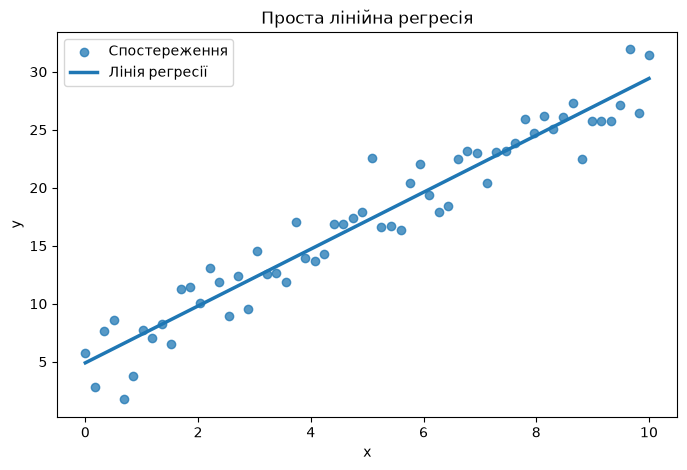

In [2]:
rng = np.random.default_rng(RANDOM_STATE)

X_simple = np.linspace(0, 10, 60).reshape(-1, 1)
y_simple = 5 + 2.4 * X_simple.ravel() + rng.normal(0, 2.5, size=len(X_simple))

simple_model = LinearRegression()
simple_model.fit(X_simple, y_simple)
y_simple_pred = simple_model.predict(X_simple)

print(f'Вільний член b0: {simple_model.intercept_:.3f}')
print(f'Коефіцієнт b1: {simple_model.coef_[0]:.3f}')

plt.figure(figsize=(8, 5))
plt.scatter(X_simple.ravel(), y_simple, alpha=0.75, label='Спостереження')
plt.plot(X_simple.ravel(), y_simple_pred, linewidth=2.5, label='Лінія регресії')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Проста лінійна регресія')
plt.legend()
plt.show()

**Що потрібно побачити.** Коефіцієнт нахилу має бути близьким до 2.4, але не обов'язково дорівнювати йому точно, оскільки дані містять шум. `fit()` оцінює параметри за навчальними даними, а `predict()` лише обчислює прогноз для заданих значень ознак.

### Самостійне завдання 1

1. Створіть новий масив `X_new` зі значеннями 2, 5 і 8.
2. Отримайте прогнози моделі.
3. Виведіть таблицю з колонками `x` та `prediction`.
4. Одним реченням поясніть зміст отриманого коефіцієнта `b1`.

In [3]:
X_new=np.array([2,5,8]).reshape(-1,1)
predictions=simple_model.predict(X_new)
display(pd.DataFrame({'x':X_new.ravel(),'prediction':predictions}))
print(f'При збільшенні x на 1 прогноз y у середньому збільшується на {simple_model.coef_[0]:.3f}.')

,x,prediction
0,2,9.809730
1,5,17.163214
2,8,24.516697


При збільшенні x на 1 прогноз y у середньому збільшується на 2.451.


## 2. Метод найменших квадратів і ручний розрахунок коефіцієнтів

Для простої регресії коефіцієнт нахилу можна обчислити без готової моделі:

$$
b_1 = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2},
\qquad
b_0 = \bar y-b_1\bar x.
$$

Чисельник у формулі для $b_1$ відображає спільну зміну $x$ і $y$, а знаменник : варіативність самої ознаки $x$. Після знаходження нахилу вільний член підбирається так, щоб пряма проходила через точку $(\bar x, \bar y)$.

In [4]:
x = np.array([1, 2, 3, 4, 5], dtype=float)
y = np.array([3.0, 5.2, 6.8, 9.1, 10.9])

x_bar = x.mean()
y_bar = y.mean()

b1_manual = ((x - x_bar) * (y - y_bar)).sum() / ((x - x_bar) ** 2).sum()
b0_manual = y_bar - b1_manual * x_bar

model_check = LinearRegression().fit(x.reshape(-1, 1), y)

print(f'Ручний розрахунок: b0={b0_manual:.4f}, b1={b1_manual:.4f}')
print(f'scikit-learn:     b0={model_check.intercept_:.4f}, b1={model_check.coef_[0]:.4f}')

Ручний розрахунок: b0=1.0900, b1=1.9700
scikit-learn:     b0=1.0900, b1=1.9700


### Самостійне завдання 2

Використайте масиви `x2 = [2, 4, 6, 8, 10]` та `y2 = [7, 11, 16, 19, 25]`. Власноруч обчисліть `b0` і `b1` за формулами, а потім перевірте результат за допомогою `LinearRegression`.

In [5]:
x2=np.array([2,4,6,8,10],dtype=float)
y2=np.array([7,11,16,19,25],dtype=float)
b1=((x2-x2.mean())*(y2-y2.mean())).sum()/((x2-x2.mean())**2).sum()
b0=y2.mean()-b1*x2.mean()
check=LinearRegression().fit(x2.reshape(-1,1),y2)
print('Вручну:',b0,b1)
print('Scikit-learn:',check.intercept_,check.coef_[0])
print('Збіг:',np.allclose([b0,b1],[check.intercept_,check.coef_[0]]))

Вручну: 2.3999999999999986 2.2
Scikit-learn: 2.4000000000000004 2.1999999999999997
Збіг: True


## 3. Множинна лінійна регресія

У випадку кількох ознак модель має вигляд

$$
\hat y = b_0+b_1x_1+b_2x_2+\dots+b_px_p.
$$

Коефіцієнт $b_j$ інтерпретується як зміна прогнозу при збільшенні ознаки $x_j$ на одну одиницю **за інших рівних умов**, тобто при фіксованих значеннях інших ознак.

Для практики використаємо вбудований набір `diabetes`, тому ноутбук не потребує завантаження даних з Інтернету.

In [6]:
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()

print('Розмір X:', X.shape)
print('Розмір y:', y.shape)
display(X.head())

Розмір X: (442, 10)
Розмір y: (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [7]:
y

0      151.0
1       75.0
2      141.0
3      206.0
4      135.0
       ...  
437    178.0
438    104.0
439    132.0
440    220.0
441     57.0
Name: target, Length: 442, dtype: float64

In [8]:
multi_model = LinearRegression()
multi_model.fit(X, y)

coef_table = pd.DataFrame({
    'feature': X.columns,
    'coefficient': multi_model.coef_
}).sort_values('coefficient', key=np.abs, ascending=False)

display(coef_table)
print(f'Intercept: {multi_model.intercept_:.3f}')

,feature,coefficient
4,s1,-792.175639
8,s5,751.273700
2,bmi,519.845920
5,s2,476.739021
3,bp,324.384646
1,sex,-239.815644
7,s4,177.063238
6,s3,101.043268
9,s6,67.626692
0,age,-10.009866


Intercept: 152.133


Зверніть увагу: великий за модулем коефіцієнт не завжди означає, що ознака є «найважливішою». Порівняння коефіцієнтів залежить від масштабу ознак та їх взаємної кореляції.

## 4. Train/test та наївний baseline

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
)

baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

linear = LinearRegression()
linear.fit(X_train, y_train)
linear_pred = linear.predict(X_test)

`DummyRegressor` не використовує закономірності в ознаках і в цьому прикладі прогнозує середнє значення цільової змінної з train. Якщо реальна модель не перевершує такий baseline, необхідно переглянути ознаки, постановку задачі або сам алгоритм.

## 5. Метрики якості регресії

У лекції розглядалися MAE, MSE, RMSE та $R^2$. Вони відповідають на різні питання.

- **MAE** показує середню абсолютну величину помилки.
- **MSE** сильніше штрафує великі помилки через піднесення залишку до квадрата.
- **RMSE** є коренем з MSE і вимірюється в тих самих одиницях, що й цільова змінна.
- **$R^2$** порівнює модель із прогнозом середнім значенням цільової змінної. На нових даних він може бути від'ємним.

In [10]:
def regression_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mean_squared_error(y_true, y_pred),
        'RMSE': root_mean_squared_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred),
        'MAPE': (np.abs(y_true - y_pred) / y_true).mean() * 100
    }

metrics_baseline = regression_metrics(y_test, baseline_pred)
metrics_linear = regression_metrics(y_test, linear_pred)

pd.DataFrame([metrics_baseline, metrics_linear], index=['DummyRegressor', 'LinearRegression'])

,MAE,MSE,RMSE,R2,MAPE
DummyRegressor,64.006461,5361.533457,73.222493,-0.011963,62.791796
LinearRegression,42.794095,2900.193628,53.853446,0.452603,37.499826


### Самостійне завдання 3

Обчисліть MAE, RMSE і $R^2$ окремо, **не використовуючи** функцію `regression_metrics`. Порівняйте `DummyRegressor` і `LinearRegression`. У Markdown-комірці нижче поясніть, яка модель краща і чому не варто робити висновок лише за однією метрикою.

In [11]:
independent_metrics=pd.DataFrame([
    {'Модель':name,'MAE':mean_absolute_error(y_test,pred),'RMSE':np.sqrt(mean_squared_error(y_test,pred)),'R²':r2_score(y_test,pred)}
    for name,pred in [('DummyRegressor',baseline_pred),('LinearRegression',linear_pred)]
]).set_index('Модель')
display(independent_metrics)

,MAE,RMSE,R²
Модель,,,
DummyRegressor,64.006461,73.222493,-0.011963
LinearRegression,42.794095,53.853446,0.452603


Лінійна регресія має RMSE 53.85, а прогноз середнім має 73.22. Лінійна модель краще використовує інформацію ознак, що також відображено в MAE та R². Однієї метрики недостатньо: RMSE сильніше реагує на великі помилки, MAE показує їх типову абсолютну величину, а R² порівнює результат із прогнозом середнім.

## 6. Залишки та діагностика моделі

Залишок для об'єкта визначається як

$$
e_i = y_i-\hat y_i.
$$

Якщо модель добре описує систематичну частину залежності, на графіку `prediction → residual` не повинно бути вираженої структури. Дуга може вказувати на нелінійність, а «воронка» : на зміну дисперсії помилки.

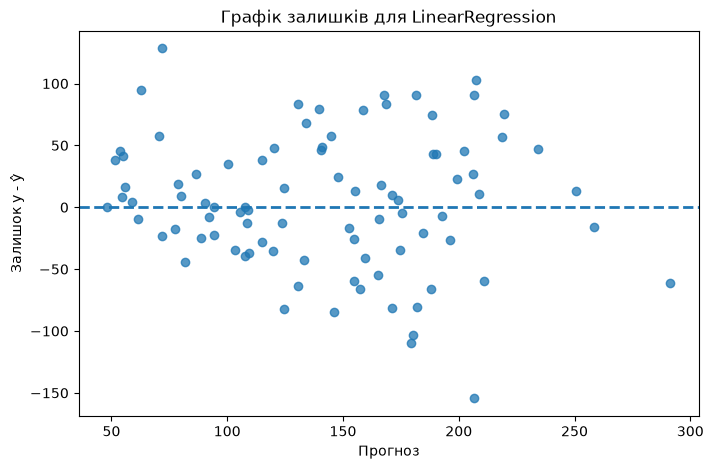

In [13]:
residuals = y_test - linear_pred

plt.figure(figsize=(8, 5))
plt.scatter(linear_pred, residuals, alpha=0.75)
plt.axhline(0, linestyle='--', linewidth=2)
plt.xlabel('Прогноз')
plt.ylabel('Залишок y - ŷ')
plt.title('Графік залишків для LinearRegression')
plt.show()

## 7. Недонавчання і перенавчання на поліноміальній регресії

Лінійна модель може недонавчатися, якщо реальна залежність нелінійна. Один зі способів збільшити гнучкість : створити поліноміальні ознаки. Але занадто високий ступінь полінома збільшує ризик перенавчання.

Порівняємо ступені 1, 4 і 15 на невеликій синтетичній вибірці.

In [14]:
rng = np.random.default_rng(RANDOM_STATE)
X_poly = np.sort(rng.uniform(-3, 3, 45)).reshape(-1, 1)
y_true_poly = np.sin(X_poly.ravel()) + 0.25 * X_poly.ravel()
y_poly = y_true_poly + rng.normal(0, 0.22, size=len(X_poly))

X_p_train, X_p_test, y_p_train, y_p_test = train_test_split(
    X_poly, y_poly, test_size=0.35, random_state=RANDOM_STATE
)

def fit_polynomial(degree):
    model = Pipeline([
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('reg', LinearRegression()),
    ])
    model.fit(X_p_train, y_p_train)
    train_pred = model.predict(X_p_train)
    test_pred = model.predict(X_p_test)
    return model, {
        'degree': degree,
        'train_rmse': root_mean_squared_error(y_p_train, train_pred),
        'test_rmse': root_mean_squared_error(y_p_test, test_pred),
    }

results = []
models_poly = {}
for degree in [1, 4, 15]:
    m, res = fit_polynomial(degree)
    models_poly[degree] = m
    results.append(res)

pd.DataFrame(results)

,degree,train_rmse,test_rmse
0,1,0.392868,0.465437
1,4,0.144969,0.203183
2,15,0.091024,0.244266


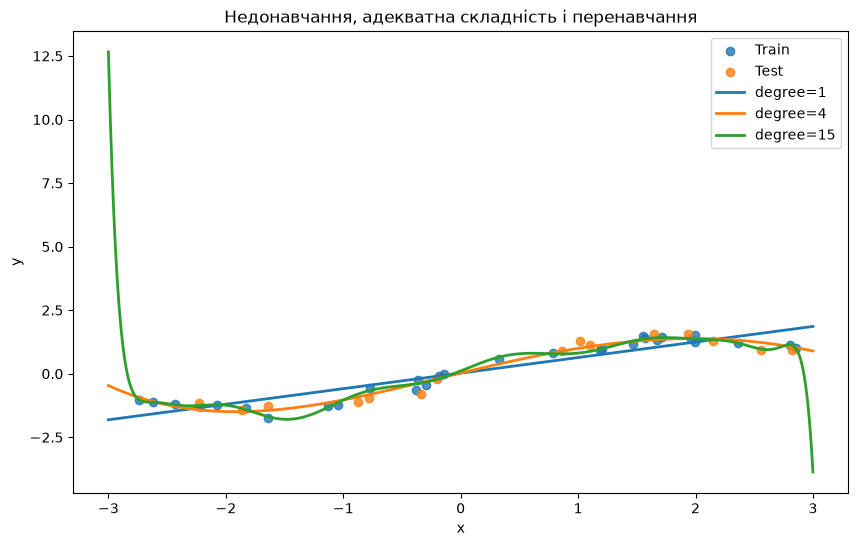

In [15]:
grid = np.linspace(-3, 3, 400).reshape(-1, 1)

plt.figure(figsize=(10, 6))
plt.scatter(X_p_train, y_p_train, label='Train', alpha=0.8)
plt.scatter(X_p_test, y_p_test, label='Test', alpha=0.8)

for degree in [1, 4, 15]:
    plt.plot(grid, models_poly[degree].predict(grid), linewidth=2, label=f'degree={degree}')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Недонавчання, адекватна складність і перенавчання')
plt.legend()
plt.show()

### Самостійне завдання 4

1. Додайте до порівняння ступені 2, 6 і 10.
2. Побудуйте таблицю `degree`, `train_rmse`, `test_rmse`.
3. Визначте ступінь із найменшим `test_rmse`.
4. Поясніть, чому мінімальна train-помилка не гарантує найкращої моделі.

In [16]:
degree_results=[]
for degree in [1,2,4,6,10,15]:
    model,result=fit_polynomial(degree)
    degree_results.append(result)
degree_table=pd.DataFrame(degree_results).sort_values('test_rmse')
display(degree_table)
print('Найменша test RMSE у демонстрації:',int(degree_table.iloc[0]['degree']))
print('Менша train-помилка може означати підлаштування під шум. Вибір за test тут навчальний; для чесної остаточної оцінки потрібен окремий validation або CV.')

,degree,train_rmse,test_rmse
4,10,0.129074,0.191782
3,6,0.137065,0.196267
2,4,0.144969,0.203183
5,15,0.091024,0.244266
1,2,0.392821,0.463992
0,1,0.392868,0.465437


Найменша test RMSE у демонстрації: 10
Менша train-помилка може означати підлаштування під шум. Вибір за test тут навчальний; для чесної остаточної оцінки потрібен окремий validation або CV.


## 8. Регуляризація: загальна ідея

Коли модель має багато ознак або ознаки сильно корельовані, коефіцієнти можуть ставати нестабільними. Регуляризація додає до функції втрат штраф за великі коефіцієнти.

Для Ridge використовується L2-штраф

$$
\text{MSE}+\alpha\sum_{j=1}^{p} b_j^2,
$$

для Lasso : L1-штраф

$$
\text{MSE}+\alpha\sum_{j=1}^{p}|b_j|.
$$

Параметр $\alpha$ керує силою регуляризації. Якщо $\alpha=0$, штраф зникає. Надто велике $\alpha$ може надмірно стиснути коефіцієнти й спричинити недонавчання.

## 9. Чому перед Ridge, Lasso та Elastic Net потрібне масштабування

In [17]:
X_scaled_demo = X.copy()
X_scaled_demo['bmi'] = X_scaled_demo['bmi'] * 1000
X_scaled_demo['bp'] = X_scaled_demo['bp'] * 0.01

Xsd_train, Xsd_test, ysd_train, ysd_test = train_test_split(
    X_scaled_demo, y, test_size=0.2, random_state=RANDOM_STATE
)

ridge_no_scaling = Ridge(alpha=10.0).fit(Xsd_train, ysd_train)
ridge_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=10.0)),
]).fit(Xsd_train, ysd_train)

print('Ridge без масштабування RMSE:', root_mean_squared_error(ysd_test, ridge_no_scaling.predict(Xsd_test)))
print('Ridge + StandardScaler RMSE:', root_mean_squared_error(ysd_test, ridge_pipeline.predict(Xsd_test)))

Ridge без масштабування RMSE: 62.25349241861677
Ridge + StandardScaler RMSE: 53.62628756889519


Штраф застосовується безпосередньо до коефіцієнтів. Якщо ознаки вимірюються в дуже різних масштабах, одна й та сама величина коефіцієнта не має однакового змісту. Тому `StandardScaler` зазвичай включають у `Pipeline` перед регуляризованою лінійною моделлю.

## 10. Ridge-регресія: L2-регуляризація

In [18]:
ridge = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=1.0)),
])

ridge.fit(X_train, y_train)
ridge_pred = ridge.predict(X_test)

print(regression_metrics(y_test, ridge_pred))

{'MAE': 42.81199941834889, 'MSE': 2892.0145657501716, 'RMSE': 53.77745406534389, 'R2': 0.45414652070698236, 'MAPE': np.float64(37.44816405198748)}


## 11. Lasso: L1-регуляризація

In [19]:
lasso = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Lasso(alpha=1.0, max_iter=20000)),
])

lasso.fit(X_train, y_train)
lasso_pred = lasso.predict(X_test)

lasso_coef = lasso.named_steps['reg'].coef_
print(regression_metrics(y_test, lasso_pred))
print('Кількість нульових коефіцієнтів:', np.sum(np.isclose(lasso_coef, 0)))

{'MAE': 42.80298373195777, 'MSE': 2824.568094049959, 'RMSE': 53.14666587896139, 'R2': 0.46687670944102466, 'MAPE': np.float64(37.43982076869067)}
Кількість нульових коефіцієнтів: 1


На відміну від Ridge, Lasso може занулювати частину коефіцієнтів. Саме тому L1-регуляризацію іноді використовують як вбудований механізм відбору ознак. Проте при сильно корельованих предикторах вибір конкретної ознаки може бути нестабільним.

## 12. Elastic Net: поєднання L1 та L2

In [20]:
elastic = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=20000)),
])

elastic.fit(X_train, y_train)
elastic_pred = elastic.predict(X_test)

print(regression_metrics(y_test, elastic_pred))

{'MAE': 42.873332243316874, 'MSE': 2866.4612552977674, 'RMSE': 53.539343060013046, 'R2': 0.4589695819678379, 'MAPE': np.float64(37.40678706534485)}


В Elastic Net параметр `alpha` визначає загальну силу регуляризації, а `l1_ratio` : співвідношення між L1 та L2. Значення `l1_ratio=1` наближає модель до Lasso, а `l1_ratio=0` : до Ridge.

### Самостійне завдання 5

Навчіть на одному й тому самому train/test розбитті чотири моделі: `LinearRegression`, `Ridge`, `Lasso`, `ElasticNet`. Для регуляризованих моделей використайте `StandardScaler` у `Pipeline`. Побудуйте таблицю з MAE, RMSE та $R^2$.

In [21]:
four_models={'LinearRegression':LinearRegression(),'Ridge':Pipeline([('scale',StandardScaler()),('reg',Ridge(alpha=1))]),'Lasso':Pipeline([('scale',StandardScaler()),('reg',Lasso(alpha=1,max_iter=20000))]),'ElasticNet':Pipeline([('scale',StandardScaler()),('reg',ElasticNet(alpha=0.1,l1_ratio=0.5,max_iter=20000))])}
four_results=[]
for name,model in four_models.items():
    model.fit(X_train,y_train)
    pred=model.predict(X_test)
    four_results.append({'Модель':name,'MAE':mean_absolute_error(y_test,pred),'RMSE':root_mean_squared_error(y_test,pred),'R²':r2_score(y_test,pred)})
display(pd.DataFrame(four_results).set_index('Модель'))

,MAE,RMSE,R²
Модель,,,
LinearRegression,42.794095,53.853446,0.452603
Ridge,42.811999,53.777454,0.454147
Lasso,42.802984,53.146666,0.466877
ElasticNet,42.873332,53.539343,0.458970


## 13. Крос-валідація

Одне train/test розбиття залежить від випадкового поділу. K-fold cross-validation кілька разів змінює validation-частину і дає більш стійку оцінку якості моделі. Важливо, що preprocessing повинен бути всередині `Pipeline`, щоб на кожному фолді параметри масштабування оцінювалися лише з train-частини.

In [22]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

ridge_cv_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=1.0)),
])

scores = cross_validate(
    ridge_cv_model,
    X,
    y,
    cv=cv,
    scoring={
        'mae': 'neg_mean_absolute_error',
        'rmse': 'neg_root_mean_squared_error',
        'r2': 'r2',
    },
    return_train_score=True,
)

cv_table = pd.DataFrame({
    'fold': np.arange(1, 6),
    'train_R2': scores['train_r2'],
    'val_R2': scores['test_r2'],
    'val_MAE': -scores['test_mae'],
    'val_RMSE': -scores['test_rmse'],
})

display(cv_table)
print('Середній validation RMSE:', cv_table['val_RMSE'].mean())

,fold,train_R2,val_R2,val_MAE,val_RMSE
0,1,0.527632,0.454147,42.811999,53.777454
1,2,0.497124,0.571674,41.616638,51.692906
2,3,0.538901,0.391921,47.224871,57.530264
3,4,0.494045,0.583169,42.166318,52.966248
4,5,0.540152,0.394449,47.397540,58.168400


Середній validation RMSE: 54.82705421208429


## 14. Підбір alpha для Ridge за GridSearchCV

In [23]:
ridge_search_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge()),
])

param_grid_ridge = {
    'reg__alpha': np.logspace(0, 5, 13)
}

ridge_search = GridSearchCV(
    ridge_search_model,
    param_grid=param_grid_ridge,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=2,
)

ridge_search.fit(X_train, y_train)

print('Найкраще alpha:', ridge_search.best_params_['reg__alpha'])
print('CV RMSE:', -ridge_search.best_score_)
print('Test RMSE:', root_mean_squared_error(y_test, ridge_search.predict(X_test)))

Найкраще alpha: 1.0
CV RMSE: 55.37417536867345
Test RMSE: 53.77745406534389


Тестову вибірку не використовують для підбору `alpha`. Гіперпараметр обирається всередині train за крос-валідацією, а test використовується лише після завершення вибору моделі.

## 15. Підбір alpha і l1_ratio для Elastic Net

In [24]:
elastic_search_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(max_iter=30000)),
])

param_grid_elastic = {
    'reg__alpha': [0.001, 0.01, 0.03, 0.1, 0.3, 1.0],
    'reg__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9],
}

elastic_search = GridSearchCV(
    elastic_search_model,
    param_grid=param_grid_elastic,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=2,
)

elastic_search.fit(X_train, y_train)

print('Найкращі параметри:', elastic_search.best_params_)
print('CV RMSE:', -elastic_search.best_score_)
print('Test RMSE:', root_mean_squared_error(y_test, elastic_search.predict(X_test)))

Найкращі параметри: {'reg__alpha': 0.03, 'reg__l1_ratio': 0.9}
CV RMSE: 55.36852020555442
Test RMSE: 53.74450007977087


### Самостійне завдання 6

Виконайте `GridSearchCV` для Lasso. Перевірте не менше 10 значень `alpha` у логарифмічній шкалі. Порівняйте найкращий Lasso з найкращим Ridge за однаковою схемою CV.

In [25]:
lasso_search=GridSearchCV(Pipeline([('scale',StandardScaler()),('reg',Lasso(max_iter=30000))]),{'reg__alpha':np.logspace(-3,2,15)},cv=cv,scoring='neg_root_mean_squared_error',n_jobs=2)
lasso_search.fit(X_train,y_train)
lasso_ridge=pd.DataFrame([
    {'Модель':name,'alpha':searcher.best_params_['reg__alpha'],'CV RMSE':-searcher.best_score_,'Test RMSE':root_mean_squared_error(y_test,searcher.predict(X_test))}
    for name,searcher in [('Ridge',ridge_search),('Lasso',lasso_search)]
])
display(lasso_ridge)

,Модель,alpha,CV RMSE,Test RMSE
0,Ridge,1.00000,55.374175,53.777454
1,Lasso,0.13895,55.349419,53.688412


## 16. Як регуляризація змінює коефіцієнти

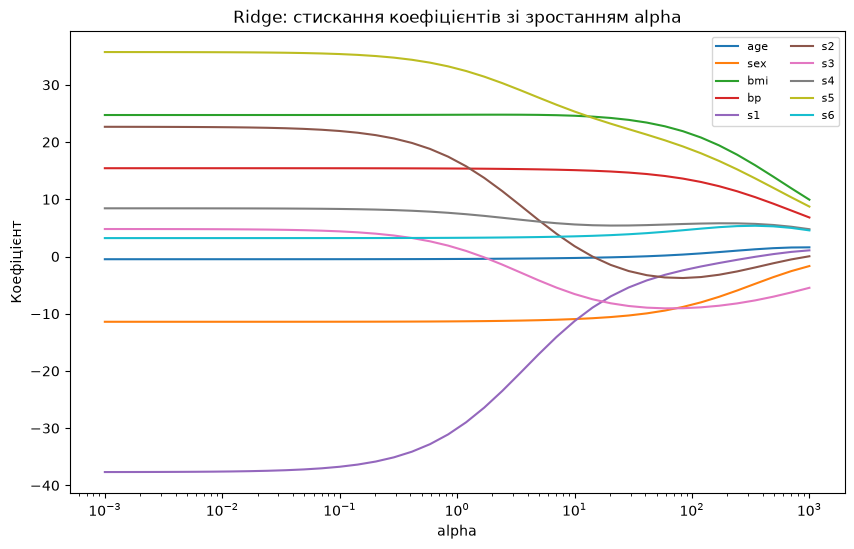

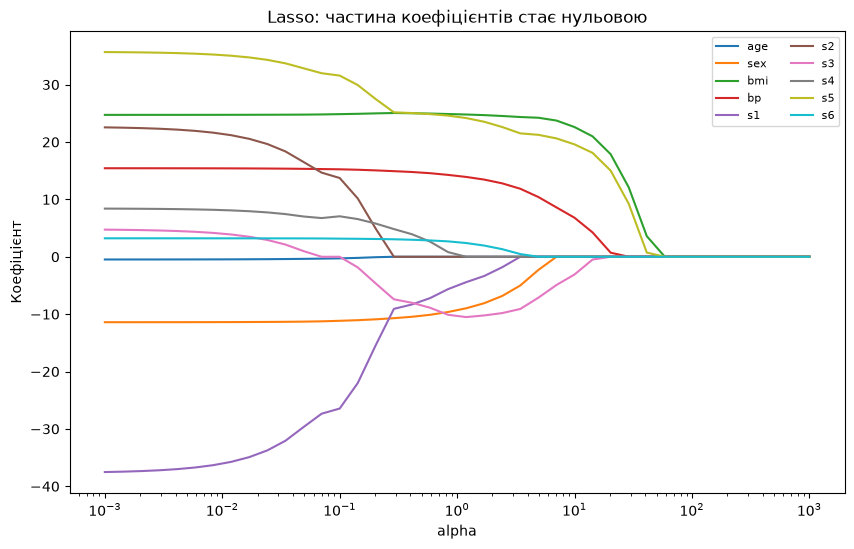

In [26]:
alphas = np.logspace(-3, 3, 40)
ridge_paths = []
lasso_paths = []

X_for_path = StandardScaler().fit_transform(X)

for alpha in alphas:
    ridge_m = Ridge(alpha=alpha).fit(X_for_path, y)
    lasso_m = Lasso(alpha=alpha, max_iter=30000).fit(X_for_path, y)
    ridge_paths.append(ridge_m.coef_)
    lasso_paths.append(lasso_m.coef_)

ridge_paths = np.array(ridge_paths)
lasso_paths = np.array(lasso_paths)

plt.figure(figsize=(10, 6))
for j, name in enumerate(X.columns):
    plt.plot(alphas, ridge_paths[:, j], label=name)
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Коефіцієнт')
plt.title('Ridge: стискання коефіцієнтів зі зростанням alpha')
plt.legend(ncol=2, fontsize=8)
plt.show()

plt.figure(figsize=(10, 6))
for j, name in enumerate(X.columns):
    plt.plot(alphas, lasso_paths[:, j], label=name)
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Коефіцієнт')
plt.title('Lasso: частина коефіцієнтів стає нульовою')
plt.legend(ncol=2, fontsize=8)
plt.show()

Ці графіки демонструють ключову різницю. Ridge плавно стискає коефіцієнти до нуля, тоді як Lasso може зробити частину з них точно нульовими.

## 17. Мультиколінеарність і стабільність коефіцієнтів

In [27]:
rng = np.random.default_rng(RANDOM_STATE)
n = 250
x1 = rng.normal(size=n)
x2 = x1 + rng.normal(scale=0.03, size=n)
x3 = rng.normal(size=n)
y_corr = 5 * x1 + 5 * x2 + 0.5 * x3 + rng.normal(scale=1.5, size=n)

X_corr = pd.DataFrame({'x1': x1, 'x2': x2, 'x3': x3})
print(X_corr.corr())

ols_corr = LinearRegression().fit(X_corr, y_corr)
ridge_corr = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=10.0)),
]).fit(X_corr, y_corr)

coef_compare = pd.DataFrame({
    'feature': X_corr.columns,
    'OLS': ols_corr.coef_,
    'Ridge_scaled': ridge_corr.named_steps['reg'].coef_,
})
coef_compare

          x1        x2        x3
x1  1.000000  0.999515 -0.008921
x2  0.999515  1.000000 -0.010420
x3 -0.008921 -0.010420  1.000000


,feature,OLS,Ridge_scaled
0,x1,5.446248,4.546617
1,x2,4.410887,4.534370
2,x3,0.444792,0.439193


За наявності дуже корельованих ознак окремі коефіцієнти OLS можуть бути нестабільними: невеликі зміни даних здатні суттєво змінити їх значення. Ridge зменшує variance коефіцієнтів завдяки L2-штрафу.

## 18. Категоріальні ознаки, пропуски та ColumnTransformer

У реальній табличній задачі дані часто містять числові й категоріальні ознаки, а також пропуски. Їх потрібно обробляти всередині `Pipeline`, щоб не створювати витік інформації.

In [28]:
rng = np.random.default_rng(RANDOM_STATE)
n = 300

housing = pd.DataFrame({
    'area': rng.normal(75, 20, n).clip(25, 150),
    'rooms': rng.integers(1, 6, n),
    'age': rng.integers(0, 70, n).astype(float),
    'district': rng.choice(['center', 'north', 'south'], n, p=[0.3, 0.35, 0.35]),
})


housing.loc[rng.choice(n, 18, replace=False), 'age'] = np.nan

price = (
    1500 * housing['area']
    + 7000 * housing['rooms']
    - 500 * housing['age'].fillna(housing['age'].median())
    + housing['district'].map({'center': 40000, 'north': 12000, 'south': 0})
    + rng.normal(0, 12000, n)
)

X_h_train, X_h_test, y_h_train, y_h_test = train_test_split(
    housing, price, test_size=0.2, random_state=RANDOM_STATE
)

numeric_features = ['area', 'rooms', 'age']
categorical_features = ['district']

numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])

categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_features),
    ('cat', categorical_pipe, categorical_features),
])

housing_model = Pipeline([
    ('prep', preprocessor),
    ('reg', Ridge(alpha=1.0)),
])

housing_model.fit(X_h_train, y_h_train)
housing_pred = housing_model.predict(X_h_test)

print('Housing RMSE:', root_mean_squared_error(y_h_test, housing_pred))
print('Housing R2:', r2_score(y_h_test, housing_pred))
print('Housing MAE:', mean_absolute_error(y_h_test, housing_pred))
print('MAPE', mean_absolute_percentage_error(y_h_test, housing_pred))

Housing RMSE: 10925.27837150392
Housing R2: 0.906890868643507
Housing MAE: 8737.023097309457
MAPE 0.07276440135248953


In [29]:
housing

,area,rooms,age,district
0,81.094342,4,17.0,south
1,54.200318,2,66.0,south
2,90.009024,2,37.0,center
3,93.811294,2,21.0,south
4,35.979296,3,29.0,south
...,...,...,...,...
295,78.530248,4,30.0,center
296,80.919880,5,45.0,center
297,67.561708,3,38.0,center
298,39.865564,3,67.0,south


In [30]:
price

0      146888.018855
1       43872.771974
2      175189.836338
3      145447.579696
4       58699.634461
           ...      
295    179796.834387
296    197085.341513
297    166868.377770
298     32562.347956
299    100221.467178
Length: 300, dtype: float64

### Самостійне завдання 7

Додайте до таблиці `housing` нову категоріальну ознаку `condition` зі значеннями `new`, `good`, `needs_repair`. Включіть її в `ColumnTransformer`, перенавчіть модель і перевірте, чи змінилася test-помилка.

In [31]:
housing_ext=housing.copy()
condition_rng=np.random.default_rng(42)
housing_ext['condition']=condition_rng.choice(['new','good','needs_repair'],len(housing_ext))
prep_ext=ColumnTransformer([
    ('num',Pipeline([('imputer',SimpleImputer(strategy='median')),('scale',StandardScaler())]),numeric_features),
    ('cat',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))]),['district','condition'])
])
model_ext=Pipeline([('prep',prep_ext),('reg',Ridge(alpha=1))])
ext_train=housing_ext.loc[X_h_train.index]
ext_test=housing_ext.loc[X_h_test.index]
model_ext.fit(ext_train,y_h_train)
ext_pred=model_ext.predict(ext_test)
print('RMSE без condition:',root_mean_squared_error(y_h_test,housing_pred))
print('RMSE з condition:',root_mean_squared_error(y_h_test,ext_pred))
print('Condition створена випадково й не входила у формулу ціни, тому стабільного покращення очікувати не слід.')

RMSE без condition: 10925.27837150392
RMSE з condition: 10804.40872275658
Condition створена випадково й не входила у формулу ціни, тому стабільного покращення очікувати не слід.


## 19. Навчальні криві

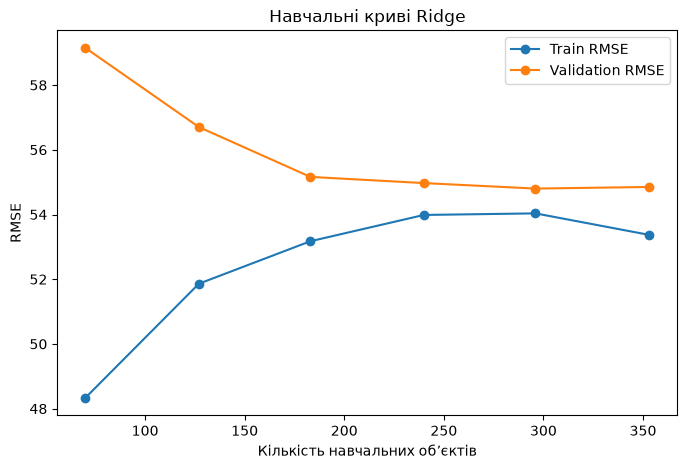

In [32]:
learning_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=ridge_search.best_params_['reg__alpha'])),
])

train_sizes, train_scores, val_scores = learning_curve(
    learning_model,
    X,
    y,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    train_sizes=np.linspace(0.2, 1.0, 6),
    n_jobs=2,
)

train_rmse_curve = -train_scores.mean(axis=1)
val_rmse_curve = -val_scores.mean(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_rmse_curve, marker='o', label='Train RMSE')
plt.plot(train_sizes, val_rmse_curve, marker='o', label='Validation RMSE')
plt.xlabel('Кількість навчальних об’єктів')
plt.ylabel('RMSE')
plt.title('Навчальні криві Ridge')
plt.legend()
plt.show()

Якщо train і validation помилки високі та близькі, це ознака можливого недонавчання. Якщо train-помилка значно нижча за validation, це може свідчити про високу variance та перенавчання. Навчальні криві допомагають зрозуміти, чи може збільшення обсягу даних бути корисним.

## 20. Повний приклад: коректний вибір моделі без використання test

In [33]:
X_final_train, X_final_test, y_final_train, y_final_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)


model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(max_iter=30000)),
])

param_grid = {
    'reg__alpha': [0.001, 0.01, 0.03, 0.1, 0.3, 1.0],
    'reg__l1_ratio': [0.1, 0.5, 0.9],
}

search = GridSearchCV(
    model,
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=2,
)
search.fit(X_final_train, y_final_train)


final_pred = search.predict(X_final_test)

print('Найкращі параметри:', search.best_params_)
print('CV RMSE:', -search.best_score_)
print('Test metrics:', regression_metrics(y_final_test, final_pred))

Найкращі параметри: {'reg__alpha': 0.03, 'reg__l1_ratio': 0.9}
CV RMSE: 55.36852020555442
Test metrics: {'MAE': 42.81393247843441, 'MSE': 2888.4712888244917, 'RMSE': 53.74450007977087, 'R2': 0.4548152967432053, 'MAPE': np.float64(37.42858410670238)}


# 21. Підсумкове практичне завдання для самостійної роботи

Виконайте повний експеримент на наборі `diabetes`. Цей блок потрібно зробити **самостійно**, використовуючи попередні приклади лише як орієнтир.

Вимоги до роботи:

1. Завантажити `load_diabetes(as_frame=True)` і переглянути структуру даних.
2. Відкласти 20% даних у test із `random_state=42`.
3. Побудувати `DummyRegressor` і `LinearRegression` як baseline.
4. Обчислити MAE, RMSE та $R^2$ на test.
5. Побудувати Ridge, Lasso та Elastic Net через `Pipeline` із `StandardScaler`.
6. Виконати 5-fold cross-validation.
7. Для Ridge і Lasso підібрати `alpha`; для Elastic Net : `alpha` та `l1_ratio`.
8. Порівняти моделі в одній таблиці.
9. Для найкращої моделі побудувати графік `фактичні значення → прогноз` та графік залишків.
10. Проаналізувати коефіцієнти найкращої лінійної моделі.
11. Сформулювати підсумковий висновок: яка модель обрана, за якою метрикою та чому.

Нижче залишені окремі комірки для кожного етапу.

### Крок 1. Дані

In [34]:
task=load_diabetes(as_frame=True)
X_task=task.data.copy()
y_task=task.target.copy()
print(X_task.shape,y_task.shape)
display(X_task.head())
X_task.info()

(442, 10) (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
dtypes: float64(10)
memory usage: 34.7 KB


### Крок 2. Train/test

In [35]:
Xt_train,Xt_test,yt_train,yt_test=train_test_split(X_task,y_task,test_size=0.2,random_state=42)
print(Xt_train.shape,Xt_test.shape)

(353, 10) (89, 10)


### Крок 3. Baseline

In [36]:
task_baselines={'DummyRegressor':DummyRegressor(strategy='mean'),'LinearRegression':LinearRegression()}
task_predictions={}
for name,model in task_baselines.items():
    model.fit(Xt_train,yt_train)
    task_predictions[name]=model.predict(Xt_test)

### Крок 4. Метрики

In [37]:
baseline_table=pd.DataFrame([
    {'Модель':name,'MAE':mean_absolute_error(yt_test,pred),'RMSE':root_mean_squared_error(yt_test,pred),'R²':r2_score(yt_test,pred)}
    for name,pred in task_predictions.items()
]).set_index('Модель')
display(baseline_table)

,MAE,RMSE,R²
Модель,,,
DummyRegressor,64.006461,73.222493,-0.011963
LinearRegression,42.794095,53.853446,0.452603


### Крок 5. Ridge, Lasso, Elastic Net

In [38]:
task_models={name:Pipeline([('scale',StandardScaler()),('reg',model)]) for name,model in {'Ridge':Ridge(),'Lasso':Lasso(max_iter=30000),'ElasticNet':ElasticNet(max_iter=30000)}.items()}
print(list(task_models))

['Ridge', 'Lasso', 'ElasticNet']


### Крок 6. Крос-валідація

In [39]:
task_cv=KFold(n_splits=5,shuffle=True,random_state=42)
all_initial={**task_baselines,**task_models}
task_cv_scores={}
for name,model in all_initial.items():
    scores=cross_validate(model,Xt_train,yt_train,cv=task_cv,scoring='neg_root_mean_squared_error')
    task_cv_scores[name]=-scores['test_score'].mean()
display(pd.Series(task_cv_scores,name='CV RMSE'))

DummyRegressor      78.133634
LinearRegression    55.394633
Ridge               55.374175
Lasso               55.388472
ElasticNet          56.658537
Name: CV RMSE, dtype: float64

### Крок 7. Підбір гіперпараметрів

In [40]:
task_grids={
    'Ridge':{'reg__alpha':np.logspace(-3,5,17)},
    'Lasso':{'reg__alpha':np.logspace(-3,2,15)},
    'ElasticNet':{'reg__alpha':[0.001,0.01,0.03,0.1,0.3,1],'reg__l1_ratio':[0.1,0.3,0.5,0.7,0.9]}
}
task_searches={}
for name,model in task_models.items():
    fitted=GridSearchCV(model,task_grids[name],cv=task_cv,scoring='neg_root_mean_squared_error',n_jobs=2)
    fitted.fit(Xt_train,yt_train)
    task_searches[name]=fitted
    print(name,fitted.best_params_,'CV RMSE:',-fitted.best_score_)

Ridge {'reg__alpha': np.float64(1.0)} CV RMSE: 55.37417536867345


Lasso {'reg__alpha': np.float64(0.13894954943731375)} CV RMSE: 55.349419183325566


ElasticNet {'reg__alpha': 0.03, 'reg__l1_ratio': 0.9} CV RMSE: 55.36852020555442


### Крок 8. Фінальна таблиця моделей

In [41]:
final_models={**task_baselines,**{name:s.best_estimator_ for name,s in task_searches.items()}}
final_cv={**task_cv_scores,**{name:-s.best_score_ for name,s in task_searches.items()}}
task_best_name=min(final_models,key=final_cv.get)
task_best_model=final_models[task_best_name]
rows=[]
for name,model in final_models.items():
    pred=model.predict(Xt_test)
    rows.append({'Модель':name,'CV RMSE':final_cv[name],'Test MAE':mean_absolute_error(yt_test,pred),'Test RMSE':root_mean_squared_error(yt_test,pred),'Test R²':r2_score(yt_test,pred),'Train RMSE':root_mean_squared_error(yt_train,model.predict(Xt_train))})
final_table=pd.DataFrame(rows).set_index('Модель').sort_values('CV RMSE')
display(final_table)
print('Вибір лише за CV:',task_best_name)

,CV RMSE,Test MAE,Test RMSE,Test R²,Train RMSE
Модель,,,,,
Lasso,55.349419,42.813370,53.688412,0.455953,53.609691
ElasticNet,55.368520,42.813932,53.744500,0.454815,53.589010
Ridge,55.374175,42.811999,53.777454,0.454147,53.575145
LinearRegression,55.394633,42.794095,53.853446,0.452603,53.558843
DummyRegressor,78.133634,64.006461,73.222493,-0.011963,77.951254


Вибір лише за CV: Lasso


### Крок 9. Візуалізація найкращої моделі

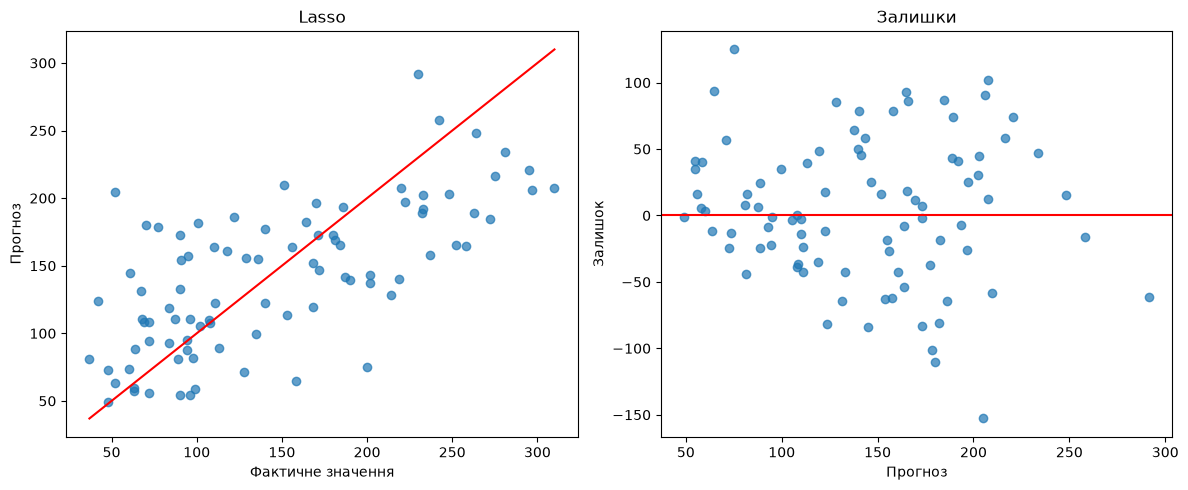

In [42]:
best_pred=task_best_model.predict(Xt_test)
fig,axes=plt.subplots(1,2,figsize=(12,5))
axes[0].scatter(yt_test,best_pred,alpha=0.7)
axes[0].plot([yt_test.min(),yt_test.max()],[yt_test.min(),yt_test.max()],color='red')
axes[0].set(xlabel='Фактичне значення',ylabel='Прогноз',title=task_best_name)
axes[1].scatter(best_pred,yt_test-best_pred,alpha=0.7)
axes[1].axhline(0,color='red')
axes[1].set(xlabel='Прогноз',ylabel='Залишок',title='Залишки')
plt.tight_layout()
plt.show()

### Крок 10. Коефіцієнти

In [43]:
if hasattr(task_best_model,'named_steps'):
    coefficients=task_best_model.named_steps['reg'].coef_
    coefficient_scale='Стандартизовані ознаки'
elif hasattr(task_best_model,'coef_'):
    coefficients=task_best_model.coef_
    coefficient_scale='Початкові ознаки'
else:
    linear_name=min(task_searches,key=lambda name:-task_searches[name].best_score_)
    coefficients=task_searches[linear_name].best_estimator_.named_steps['reg'].coef_
    coefficient_scale='Найкраща регуляризована лінійна модель: '+linear_name
task_coefficients=pd.DataFrame({'Ознака':X_task.columns,'Коефіцієнт':coefficients}).sort_values('Коефіцієнт',key=abs,ascending=False)
print(coefficient_scale)
display(task_coefficients)

Стандартизовані ознаки


,Ознака,Коефіцієнт
8,s5,28.762469
4,s1,-27.248289
2,bmi,25.898173
3,bp,16.598909
5,s2,11.444106
1,sex,-11.214936
7,s4,10.323913
9,s6,2.394047
0,age,1.699222
6,s3,-0.000000


### Крок 11. Підсумковий висновок

У новій Markdown-комірці після цієї сформулюйте висновок обсягом 5-8 речень. Обов'язково зазначте:

- яка модель показала найкращий результат;
- за якою метрикою виконано вибір;
- чи є ознаки перенавчання;
- як регуляризація вплинула на результат;
- чому test не використовувався під час підбору гіперпараметрів.

За мінімальною середньою RMSE на 5-fold CV всередині train обрано **Lasso**: CV RMSE=55.35. На відкладеному test модель має MAE=42.81, RMSE=53.69, R²=0.4560. Для LinearRegression test RMSE становить 53.85, тому фактичний вплив регуляризації видно у спільній таблиці, а її перевага не припускається наперед. Train RMSE обраної моделі дорівнює 53.61; різницю з CV/test слід оцінювати з урахуванням невеликої вибірки з 442 об’єктів, тому одного поділу недостатньо для категоричного висновку про перенавчання. Найбільші за модулем коефіцієнти мають s5, s1, bmi, але їх інтерпретація залежить від масштабу та кореляції ознак. Ridge стискає коефіцієнти, Lasso може занулювати їх, Elastic Net поєднує обидва штрафи. Test не використовувався для підбору параметрів фінального експерименту, а StandardScaler усередині Pipeline навчався окремо на кожному train-згині.